In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    cross_validate
)
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    root_mean_squared_error
)

In [2]:
SEED = 42

FEATURE_COLS = [
    "Age", "Weight_kg", "Height_m",
    "Max_BPM", "Avg_BPM", "Resting_BPM",
    "Session_Duration_min", "Fat_Percentage",
    "Water_Intake_liters", "BMI"
]

df = pd.read_csv(
    "../backend/data/gym_members_clean.csv"
)

X = df[FEATURE_COLS]
y = df["Calories_Burned"]

print(df.shape)
print(X.shape)
print(y.shape)

(973, 14)
(973, 10)
(973,)


In [3]:
Xtr, Xte, ytr, yte = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=SEED
)

print("training set:" , Xtr.shape)
print("testing set:", Xte.shape)

training set: (778, 10)
testing set: (195, 10)


In [4]:
baseline = DummyRegressor(
    strategy="mean"
)

baseline.fit(Xtr, ytr)

baseline_pred = baseline.predict(Xte)

In [5]:
linear_model = LinearRegression()

linear_model.fit(Xtr, ytr)

linear_pred = linear_model.predict(Xte)

In [6]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    random_state=SEED
)

rf_model.fit(Xtr, ytr)

rf_pred = rf_model.predict(Xte)

In [7]:
def evaluate_model(model, X_test, y_test):
    predictions = model.predict(X_test)

    return {
        "R2": r2_score(y_test, predictions),

        "MAE": mean_absolute_error(
            y_test, predictions
        ),
        "RMSE": root_mean_squared_error(
            y_test, predictions
        )
    }    

In [8]:
models = {
    "Mean Baseline": baseline,
    "Linear Regression": linear_model,
    "Random Forest": rf_model
}

results = {}

for name, model in models.items():
    results[name] = evaluate_model(
        model, Xte, yte
    )

results_df = pd.DataFrame(results).T

print("\nTest Set Results:")

display(results_df.round(4))


Test Set Results:


,R2,MAE,RMSE
Mean Baseline,-0.0006,231.2048,288.9181
Linear Regression,0.9735,36.1777,46.9780
Random Forest,0.9690,38.7065,50.8715


In [9]:
cv_results = {}

for name, model in models.items():

    scores = cross_validate(
        model,
        Xtr,
        ytr,
        cv=5,
        scoring="r2"
    )

    cv_results[name] = scores["test_score"].mean()


# Convert results into a DataFrame

cv_df = pd.DataFrame.from_dict(
    cv_results,
    orient="index",
    columns=["Mean CV R2"]
)

print("\nCross-Validation Results:")

display(cv_df.round(4))


Cross-Validation Results:


,Mean CV R2
Mean Baseline,-0.0047
Linear Regression,0.9702
Random Forest,0.9642


In [10]:
cv_mean = cv_df.mean()

print("\nCross-Validation Results:\n")
print(cv_mean)


Cross-Validation Results:

Mean CV R2    0.643212
dtype: float64


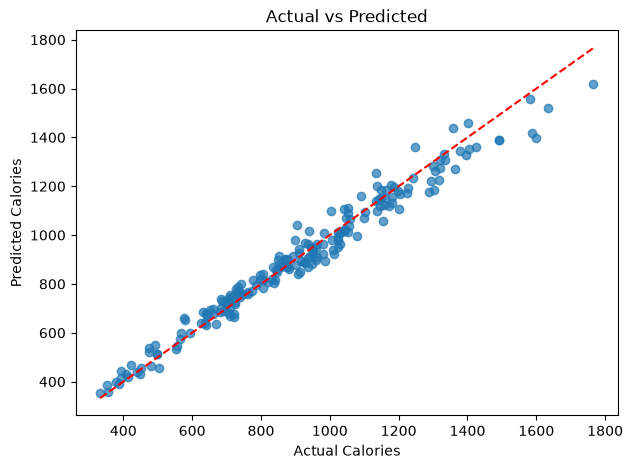

In [11]:

plt.figure(figsize=(7, 5))

plt.scatter(yte, rf_pred, alpha=0.7)

plt.plot(
    [yte.min(), yte.max()],
    [yte.min(), yte.max()],
    "r--"
)

plt.xlabel("Actual Calories")
plt.ylabel("Predicted Calories")
plt.title("Actual vs Predicted")

plt.savefig(
    "plots/actual_vs_predicted.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

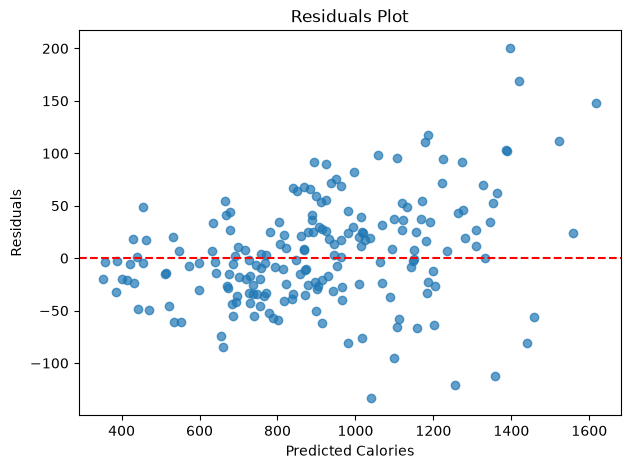

In [12]:
residuals = yte - rf_pred

plt.figure(figsize=(7, 5))

plt.scatter(rf_pred, residuals, alpha=0.7)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Calories")
plt.ylabel("Residuals")
plt.title("Residuals Plot")

plt.savefig(
    "plots/residuals.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [13]:
Xtr_new = Xtr.copy()
Xte_new = Xte.copy()

Xtr_new["Duration_BPM"] = (
    Xtr_new["Session_Duration_min"]
    * Xtr_new["Avg_BPM"]
)

Xte_new["Duration_BPM"] = (
    Xte_new["Session_Duration_min"]
    * Xte_new["Avg_BPM"]
)
print( "\nOriginal number of features:", Xtr.shape[1])

print( "New number of features:",  Xtr_new.shape[1])


Original number of features: 10
New number of features: 11


In [14]:
rf_new = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    random_state=SEED
)

rf_new.fit(Xtr_new, ytr)
rf_new_results = evaluate_model(rf_new,Xte_new,yte)


In [15]:
importance = pd.Series(
    rf_model.feature_importances_,
    index=FEATURE_COLS
)

importance = importance.sort_values(
    ascending=False
)

importance

Session_Duration_min    0.832275
Avg_BPM                 0.101440
Age                     0.020928
Fat_Percentage          0.017276
Height_m                0.006507
Water_Intake_liters     0.006140
Weight_kg               0.005793
BMI                     0.003605
Resting_BPM             0.003037
Max_BPM                 0.003000
dtype: float64

In [16]:
comparison_df = pd.DataFrame(
    {
        "Original RF": results_df.loc[
            "Random Forest"
        ],

        "RF with New Feature": rf_new_results
    }
).T

print("\nFeature Engineering Comparison:")

display(comparison_df.round(4))



Feature Engineering Comparison:


,R2,MAE,RMSE
Original RF,0.9690,38.7065,50.8715
RF with New Feature,0.9892,21.6755,30.0566


In [17]:
original_cv_r2 = cv_results["Random Forest"]

rf_new_cv = cross_validate(
    rf_new,
    Xtr_new,
    ytr,
    cv=5,
    scoring="r2"
)

new_cv_r2 = rf_new_cv["test_score"].mean()


print(
    "\nOriginal Random Forest CV R2:",
    round(float(original_cv_r2), 4)
)

print(
    "New Random Forest CV R2:",
    round(float(new_cv_r2), 4)
)


if new_cv_r2 > original_cv_r2:

    print(
        "The new feature improved the average CV R2."
    )

elif new_cv_r2 < original_cv_r2:

    print(
        "The new feature reduced the average CV R2."
    )

else:

    print(
        "The new feature did not change the average CV R2."
    )


Original Random Forest CV R2: 0.9642
New Random Forest CV R2: 0.9822
The new feature improved the average CV R2.


In [18]:
importance = pd.Series(
    rf_new.feature_importances_,
    index=Xtr_new.columns
)

importance = importance.sort_values(
    ascending=False
)

print("\nFeature Importance:")

display(importance)


Feature Importance:


Duration_BPM            0.947565
Age                     0.025575
Weight_kg               0.006997
Water_Intake_liters     0.005876
Fat_Percentage          0.005279
Height_m                0.003609
BMI                     0.001259
Avg_BPM                 0.001054
Max_BPM                 0.000987
Session_Duration_min    0.000906
Resting_BPM             0.000893
dtype: float64

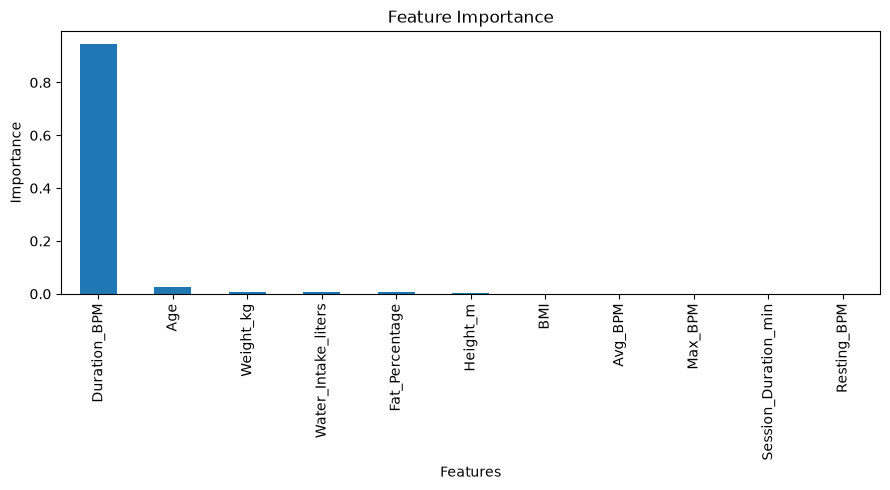

In [19]:
importance.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Feature Importance")

plt.ylabel("Importance")
plt.xlabel("Features")

plt.tight_layout()

plt.savefig(
    "plots/feature_importance.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

Results Summary:
1. The Mean Baseline performed poorly, showing that predicting the average calorie value is not sufficient.
2. Linear Regression achieved an R² of 0.9702, demonstrating a strong linear relationship between the features and calories burned.
3. Random Forest achieved an R² of 0.9642, slightly outperforming Linear Regression on the test set.
4. The similar performance suggests that the relationship between the features and calories burned is largely linear.
5. Both models provided accurate predictions, while Random Forest captured any additional non-linear patterns in the data.

